# Auswendig gelernt

Ein Netz bekommt 1'000 handgeschriebene Ziffern. Nach 150 Durchgängen macht es auf diesen 1'000 Bildern keinen Fehler mehr. Die Frage ist, was es auf Ziffern macht, die es nie gesehen hat.

In vier Schritten:

1. Daten ansehen
2. Netz bauen und trainieren
3. Die Probe: zufällige Labels
4. Was dagegen hilft

### Pflicht (rund 10 Minuten)

1. Die Abschnitte 1 bis 3 ausführen: der Grundfall und die Probe mit zufälligen Labels. Ein Lauf dauert in Colab rund eine Minute. Bei beiden die Endwerte der Validierung ablesen.
2. In Abschnitt 4 die Variante eintragen, die euer Paar rechnet: `"dropout"`, `"weight_decay"` oder `"mehr_daten"`. Zelle ausführen, Loss und Trefferquote am Ende notieren. Danach vergleicht der Raum die Endwerte.

### Zusatz (für Schnelle)

Die eigenen Endwerte mit der Tabelle unter Abschnitt 4 vergleichen. Dann eine zweite Variante rechnen oder einen eigenen Wert ausprobieren, etwa `trainiere(dropout=0.2)` oder `trainiere(anzahl_bilder=3_000, epochen=50)`.

## 1. Daten ansehen

MNIST: Ziffern mit 28 × 28 Pixeln. Wir trainieren absichtlich nur mit 1'000 Bildern. Die 10'000 Validierungsbilder sieht das Netz beim Training nie.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/overfitting")

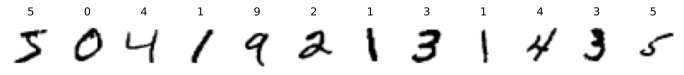

10'000 Bilder zum Prüfen


In [1]:
import numpy as np
import torch

from helfer import vergleiche_laeufe, zeige_lauf, zeige_ziffern

daten = np.load("daten/mnist-auszug.npz")
alle_bilder = torch.tensor(daten["x_training"], dtype=torch.float32).flatten(1) / 255
alle_label = torch.tensor(daten["y_training"], dtype=torch.long)
validierung_bilder = torch.tensor(daten["x_validierung"], dtype=torch.float32).flatten(1) / 255
validierung_label = torch.tensor(daten["y_validierung"], dtype=torch.long)

zeige_ziffern(daten["x_training"], daten["y_training"])
print(f"{len(validierung_label):_} Bilder zum Prüfen".replace("_", "'"))

## 2. Netz bauen und trainieren

784 Eingänge, eine Hidden Layer mit 512 Neuronen, 10 Ausgänge. Die Schleife hat dieselben vier Schritte wie beim Vogel: Vorhersage, Fehler messen, Gradient, Gewichte anpassen. Nach jeder Epoche messen wir auf beiden Töpfen.

In [2]:
from torch import nn

fehlerfunktion = nn.CrossEntropyLoss()


def messe(netz, bilder, label):
    netz.eval()
    with torch.no_grad():
        vorhersage = netz(bilder)
    return fehlerfunktion(vorhersage, label).item(), (vorhersage.argmax(1) == label).float().mean().item()


def trainiere(anzahl_bilder=1000, epochen=150, dropout=0.0, weight_decay=0.0, labels_zufaellig=False, seed=0):
    torch.manual_seed(seed)
    bilder, label = alle_bilder[:anzahl_bilder], alle_label[:anzahl_bilder]
    if labels_zufaellig:
        label = label[torch.randperm(anzahl_bilder)]

    netz = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Dropout(dropout), nn.Linear(512, 10))
    optimierer = torch.optim.AdamW(netz.parameters(), lr=0.001, weight_decay=weight_decay)
    lauf = {"bilder": anzahl_bilder, "loss_training": [], "loss_validierung": [], "treffer_training": [], "treffer_validierung": []}

    for epoche in range(epochen):
        netz.train()
        for stapel in torch.randperm(anzahl_bilder).split(32):
            vorhersage = netz(bilder[stapel])                  # Vorhersage
            loss = fehlerfunktion(vorhersage, label[stapel])   # Fehler messen
            optimierer.zero_grad()
            loss.backward()                                    # Gradient
            optimierer.step()                                  # Gewichte anpassen

        loss_t, treffer_t = messe(netz, bilder, label)
        loss_v, treffer_v = messe(netz, validierung_bilder, validierung_label)
        lauf["loss_training"].append(loss_t)
        lauf["treffer_training"].append(treffer_t)
        lauf["loss_validierung"].append(loss_v)
        lauf["treffer_validierung"].append(treffer_v)

    lauf["beste_epoche"] = int(np.argmin(lauf["loss_validierung"])) + 1
    return lauf


def bericht(lauf):
    beste = lauf["beste_epoche"]
    print(f"Training am Ende:    Loss {lauf['loss_training'][-1]:.4f}, {lauf['treffer_training'][-1]:.1%} richtig")
    print(f"Validierung, Minimum: Loss {lauf['loss_validierung'][beste - 1]:.3f} in Epoche {beste}")
    print(f"Validierung am Ende: Loss {lauf['loss_validierung'][-1]:.3f}, {lauf['treffer_validierung'][-1]:.1%} richtig")

Dauer: 9.2 Sekunden

Training am Ende:    Loss 0.0000, 100.0% richtig
Validierung, Minimum: Loss 0.374 in Epoche 5
Validierung am Ende: Loss 0.596, 89.7% richtig


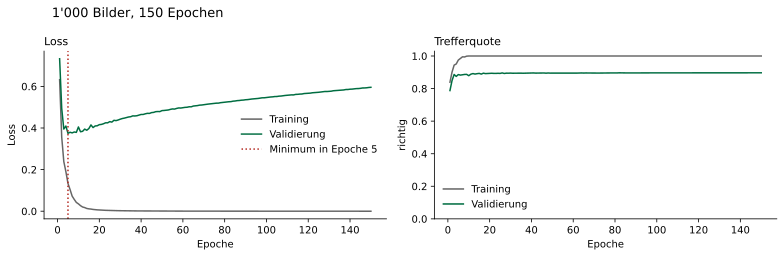

In [3]:
import time

start = time.perf_counter()
grundfall = trainiere()
print(f"Dauer: {time.perf_counter() - start:.1f} Sekunden\n")

bericht(grundfall)
zeige_lauf(grundfall, "1'000 Bilder, 150 Epochen")

Links die bekannte Schere: Der Trainings-Loss geht gegen null, der Validierungs-Loss steigt nach wenigen Epochen wieder. Das ist Overfitting.

Rechts steht, was dabei nicht passiert: Die Trefferquote auf der Validierung bleibt rund 90 %. Das Netz wird nicht schlechter im Erkennen, es wird nur immer überzeugter, auch dort, wo es falsch liegt. Der Loss bestraft genau das. Für Accuracy und Loss kann die Antwort auf „ab wann ist es Overfitting?“ deshalb verschieden ausfallen.

## 3. Die Probe: zufällige Labels

Wenn das Netz wirklich auswendig lernen kann, muss es das auch ohne jede Regel schaffen. Also würfeln wir die Labels der 1'000 Bilder neu. Eine 3 heisst jetzt vielleicht 7, und es gibt nichts mehr zu verstehen.

Training am Ende:    Loss 0.0013, 100.0% richtig
Validierung, Minimum: Loss 2.280 in Epoche 2
Validierung am Ende: Loss 7.111, 10.7% richtig


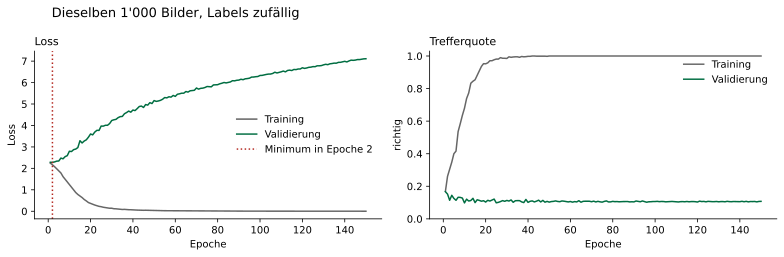

In [4]:
zufall = trainiere(labels_zufaellig=True)

bericht(zufall)
zeige_lauf(zufall, "Dieselben 1'000 Bilder, Labels zufällig")

Im Training 100 %, in der Validierung 10 %, also Raten bei zehn Ziffern. Dasselbe Netz, dieselbe Schleife, derselbe Trainings-Loss von fast null.

Ein Netz dieser Grösse kann 1'000 beliebige Zuordnungen speichern. Ein Trainings-Loss von null sagt deshalb nichts darüber, ob es etwas gelernt hat, das über die Trainingsdaten hinaus gilt. Das zeigt nur die Validierung. (Zhang et al. 2017 haben das an grossen Bildnetzen gezeigt.)

## 4. Was dagegen hilft

Drei Gegenmittel, jedes Paar rechnet eines: `"dropout"` (Dropout 0.5), `"weight_decay"` (Weight Decay 1.0) oder `"mehr_daten"` (10'000 statt 1'000 Bilder). Jeder Lauf sieht gleich viele Bilder: 150 Epochen mit 1'000 Bildern oder 15 Epochen mit 10'000. Die Grafik zeigt den Grundfall gegen die gewählte Variante.

Dauer: 4.6 Sekunden



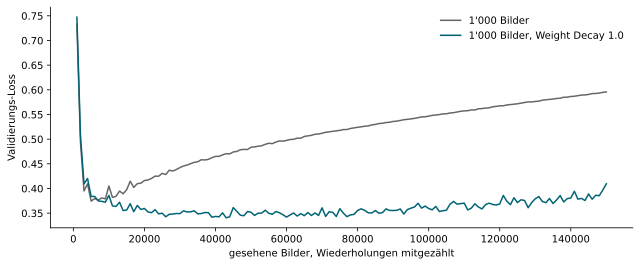

                                  Loss-Minimum  Loss am Ende   richtig
1'000 Bilder                             0.374         0.596     89.7%
1'000 Bilder, Weight Decay 1.0           0.341         0.410     89.7%


In [5]:
VARIANTE = "weight_decay"  # "dropout", "weight_decay" oder "mehr_daten"

VARIANTEN = {
    "dropout": ("1'000 Bilder, Dropout 0.5", {"dropout": 0.5}),
    "weight_decay": ("1'000 Bilder, Weight Decay 1.0", {"weight_decay": 1.0}),
    "mehr_daten": ("10'000 Bilder", {"anzahl_bilder": 10_000, "epochen": 15}),
}
if VARIANTE not in VARIANTEN:
    raise ValueError(f"Unbekannte Variante {VARIANTE!r}, möglich sind: {', '.join(VARIANTEN)}")

name, einstellung = VARIANTEN[VARIANTE]
start = time.perf_counter()
laeufe = {"1'000 Bilder": grundfall, name: trainiere(**einstellung)}
print(f"Dauer: {time.perf_counter() - start:.1f} Sekunden\n")

vergleiche_laeufe(laeufe)
print(f"{'':32}{'Loss-Minimum':>14}{'Loss am Ende':>14}{'richtig':>10}")
for name, lauf in laeufe.items():
    minimum = min(lauf["loss_validierung"])
    print(f"{name:32}{minimum:>14.3f}{lauf['loss_validierung'][-1]:>14.3f}{lauf['treffer_validierung'][-1]:>10.1%}")

Zum Vergleich alle Läufe, gemittelt über fünf Seeds. Die Zahlen oben stammen von einem Seed und weichen deshalb leicht ab.

| Lauf | Loss-Minimum | Loss am Ende | richtig am Ende |
|---|---|---|---|
| 1'000 Bilder | 0.365 | 0.570 | 90,0 % |
| Dropout 0.5 | 0.347 | 0.590 | 90,3 % |
| Weight Decay 0.1 | 0.364 | 0.468 | 90,2 % |
| Weight Decay 1.0 | 0.332 | 0.381 | 90,2 % |
| 10'000 Bilder | 0.138 | 0.151 | 96,5 % |
| 1'000 Bilder, Labels zufällig | 2.316 | 7.146 | 10,6 % |

Weight Decay dämpft den Anstieg des Losses, Dropout ändert hier kaum etwas, und an der Trefferquote ändern beide wenig. Zehnmal mehr Daten drücken die falschen Ziffern von rund 10 % auf rund 4 %.

Das gilt für dieses kleine Beispiel und ist keine Rangliste für jedes Problem. Die Reihenfolge der Fragen stimmt aber meistens: zuerst, ob es mehr oder bessere Daten gibt, danach kommen die Stellschrauben am Modell.